In [2]:
import numpy as np
import matplotlib.pyplot as plt
import re
import os
import ase.io as aio


In [870]:
#DENSITY HISTOGRAMS
surface_u='_u'
surface_d='_d'

dict_density_hist={}

folder_hist="/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/full_coverage_big/run_2/histogram_density/"
types=['H', 'O']
hist_str='_hist'
regions=['', '_oct', '_tet' ]

    
py_extension='.npy'
for type in types:
    for reg in regions:
        print(type+reg+hist_str )
        dict_density_hist[type+reg+hist_str+surface_d] =   np.load(folder_hist+type+reg+hist_str+surface_d+py_extension, allow_pickle=True)
        dict_density_hist[type+reg+hist_str+surface_u] =   np.load(folder_hist+type+reg+hist_str+surface_u+py_extension, allow_pickle=True)
        dict_density_hist[type+reg+hist_str] =   dict_density_hist[type+reg+hist_str+surface_u]+dict_density_hist[type+reg+hist_str+surface_d]
        
bins_centers=dict_density_hist['H_hist_u'][0]

dx=(bins_centers[-1]-bins_centers[0])/(len(bins_centers)-1)
f=36
t=np.load(folder_hist+'tot_time.npy')

param_big=True

H_hist
H_oct_hist
H_tet_hist
O_hist
O_oct_hist
O_tet_hist


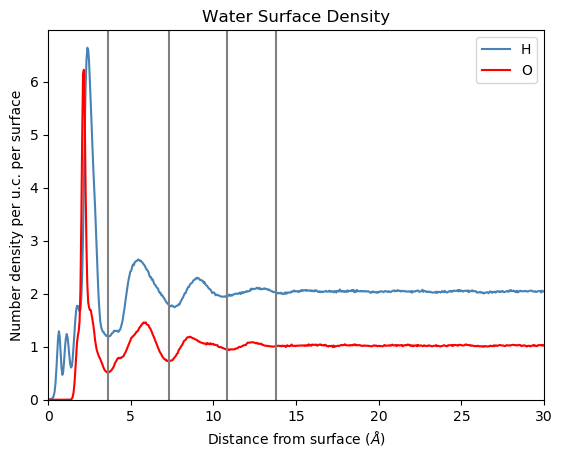

In [872]:
#surface separate:

plt.plot(bins_centers, dict_density_hist['H_hist'+surface_u][1]/(t*dx*f), label='H', color='steelblue')    #/(N_H*dx) = /(dict_density_hist['H_hist'][2]*dx) for normalization
plt.plot(bins_centers, dict_density_hist['O_hist'+surface_u][1]/(t*dx*f), label='O', color='r')
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Water Surface Density")
plt.xlim(0,30)
plt.ylim(0)
#plt.savefig(f"W_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)
if param_big:
    plt.axvline(x=3.6, color="grey")
    plt.axvline(x=7.3, color="grey")
    plt.axvline(x=10.8,  color="grey")
    plt.axvline(x=13.8,  color="grey")
else:
    plt.axvline(x=3.6, color="grey")
    plt.axvline(x=7.2, color="grey")
    plt.axvline(x=10.6,  color="grey")
    plt.axvline(x=13.8,  color="grey")    
plt.show()

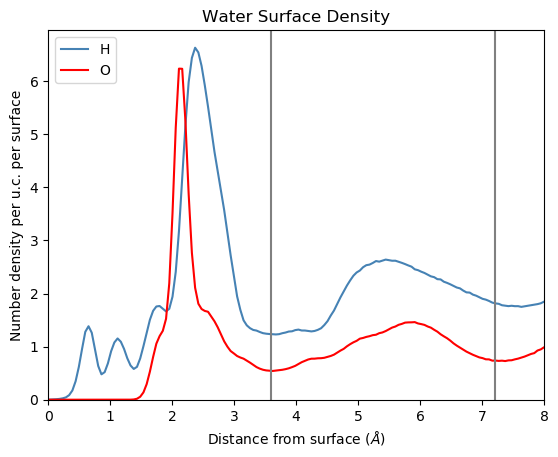

In [874]:
#surface together
plt.plot(bins_centers, dict_density_hist['H_hist'][1]/(2*t*dx*f), label='H', color='steelblue')    #/(N_H*dx) = /(dict_density_hist['H_hist'][2]*dx) for normalization
plt.plot(bins_centers, dict_density_hist['O_hist'][1]/(2*t*dx*f), label='O', color='r')
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Water Surface Density")
plt.xlim(0,8)
plt.ylim(0)
#plt.savefig(f"W_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)
plt.axvline(x=3.6, color="grey")
plt.axvline(x=7.2, color="grey")
plt.axvline(x=10.6,  color="grey")
plt.axvline(x=10.6,  color="grey")
plt.axvline(x=13.8,  color="grey")
plt.show()

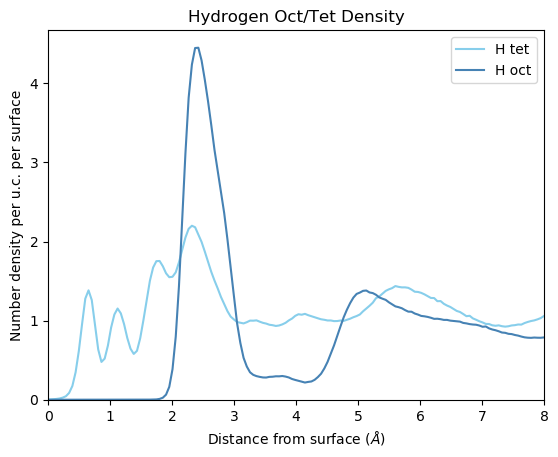

In [876]:

plt.plot(bins_centers,dict_density_hist['H_tet_hist'][1]/(2*t*dx*f), label='H tet',  color='skyblue')  #/(N_O_oct*t*dx) for normalization
plt.plot(bins_centers,dict_density_hist['H_oct_hist'][1]/(2*t*dx*f), label='H oct',  color='steelblue')  #/(N_O_oct*t*dx) for normalization
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Hydrogen Oct/Tet Density")
plt.xlim(0,8)
plt.ylim(0)

#plt.savefig(f"H_oct_tet_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)
plt.show()

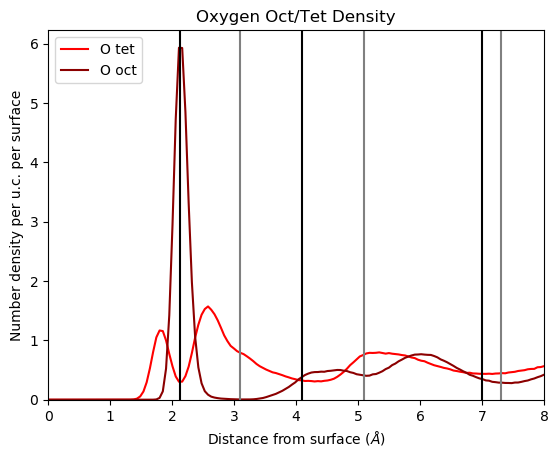

In [878]:
plt.plot(bins_centers,dict_density_hist['O_tet_hist'][1]/(2*t*dx*f),label='O tet',   color='r')
plt.plot(bins_centers,dict_density_hist['O_oct_hist'][1]/(2*t*dx*f),label='O oct',   color='darkred')
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Oxygen Oct/Tet Density")

plt.axvline(x=3.1,  color="grey")
plt.axvline(x=5.1,  color="grey")
plt.axvline(x=7.3,  color="grey")
plt.axvline(x=10,  color="grey")
plt.axvline(x=13.5,  color="grey")
plt.axvline(x=2.12,  color="black")
plt.axvline(x=4.1,  color="black")
plt.axvline(x=7,  color="black")
plt.axvline(x=10.6,  color="black")
plt.xlim(0,8)
plt.ylim(0)
#plt.savefig(f"O_oct_tet_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)
plt.show()

In [848]:
#peak integration

H_hist_uc_surface=H_hist/(t*dx*f)

mask_H_first_peak=np.where(bins_centers<0.93)[0]
mask_H_second_peak=np.where( (0.9 < bins_centers ) & ( bins_centers < 1.4) )[0]
mask_H_third_peak=np.where( (1.4 < bins_centers ) & ( bins_centers < 1.9) )[0]

print("H first peak = " , np.trapz(H_hist_uc_surface[mask_H_first_peak]  ,bins_centers[mask_H_first_peak] ))
print("H second peak = " ,np.trapz(H_hist_uc_surface[mask_H_second_peak]  ,bins_centers[mask_H_second_peak] ))
print("H third peak = " ,np.trapz(H_hist_uc_surface[mask_H_third_peak]    ,bins_centers[mask_H_third_peak] ))


O_hist_uc_surface=O_hist/(t*dx*f)

mask_O_first_peak=np.where(bins_centers<3.5)[0]
mask_O_second_peak=np.where( (3.5 < bins_centers ) & ( bins_centers < 7.5) )[0]


print("O first peak = " , np.trapz(H_hist_uc_surface[mask_O_first_peak]  ,bins_centers[mask_O_first_peak] ))
print("O second peak = " ,np.trapz(H_hist_uc_surface[mask_O_second_peak]  ,bins_centers[mask_O_second_peak] ))

NameError: name 'H_hist' is not defined

In [744]:
def reorder_phi(arr, n):
    arr=list(arr)
    if n < 0 or n >= len(arr):
        raise ValueError("Invalid value of n")

    return arr[n:] + arr[:n]


n=np.where(phi_bins_centers > -np.pi/2 )[0][0]

In [886]:
# ANGULAR HISTOGRAMS

path_of_runs='/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/'
run_folder='full_coverage_big/run_2/'

folder_hist_ang=path_of_runs+run_folder+"histogram_angular/"
dict_hist={}
dict_hist_u={}
dict_hist_d={}
surface_selection_u='_u'
surface_selection_d='_d'

name_internals=['rho', 'theta', 'phi']
hist_str='_hist_'
category=['dipole', 'OH_water', 'OH' ]
regions=['','_oct', '_tet' ]
py_extension='.npy'
for name in name_internals:
    for cat in category:
        for reg in regions:
            file=name+hist_str+cat+reg

            dict_hist_u[file+surface_selection_u] =   np.load(folder_hist_ang+file+surface_selection_u+py_extension, allow_pickle=True)
            dict_hist_d[file+surface_selection_d] =   np.load(folder_hist_ang+file+surface_selection_d+py_extension, allow_pickle=True)
         

In [887]:
rho_bins_centers=dict_hist_u["rho_hist_OH_water_u"][0]
theta_bins_centers=dict_hist_u["theta_hist_OH_water_u"][0]
phi_bins_centers=dict_hist_u["phi_hist_OH_water_u"][0]

n_bins_centers=len(rho_bins_centers)

d_rho  =(rho_bins_centers[-1]-rho_bins_centers[0])/(n_bins_centers-1)
d_theta=(theta_bins_centers[-1]-theta_bins_centers[0])/(n_bins_centers-1)
d_phi  =(phi_bins_centers[-1]-phi_bins_centers[0])/(n_bins_centers-1)

In [888]:
dict_hist={}
for i, dict_tot in dict_hist_u.items():
    print(i[:-2])
    dict_hist[i[:-2]]=[ dict_hist_u[i][0], {} , {} , {}]
    for l in dict_tot[1].keys():
        dict_hist[i[:-2]][1][l]=    dict_hist_u[i][1][l]+dict_hist_d[i[:-2]+'_d'][1][l]
        dict_hist[i[:-2]][2][l]=    dict_hist_u[i][2][l]+dict_hist_d[i[:-2]+'_d'][2][l]
        dict_hist[i[:-2]][3][l]=    dict_hist_u[i][3][l]+dict_hist_d[i[:-2]+'_d'][3][l]

rho_hist_dipole
rho_hist_dipole_oct
rho_hist_dipole_tet
rho_hist_OH_water
rho_hist_OH_water_oct
rho_hist_OH_water_tet
rho_hist_OH
rho_hist_OH_oct
rho_hist_OH_tet
theta_hist_dipole
theta_hist_dipole_oct
theta_hist_dipole_tet
theta_hist_OH_water
theta_hist_OH_water_oct
theta_hist_OH_water_tet
theta_hist_OH
theta_hist_OH_oct
theta_hist_OH_tet
phi_hist_dipole
phi_hist_dipole_oct
phi_hist_dipole_tet
phi_hist_OH_water
phi_hist_OH_water_oct
phi_hist_OH_water_tet
phi_hist_OH
phi_hist_OH_oct
phi_hist_OH_tet


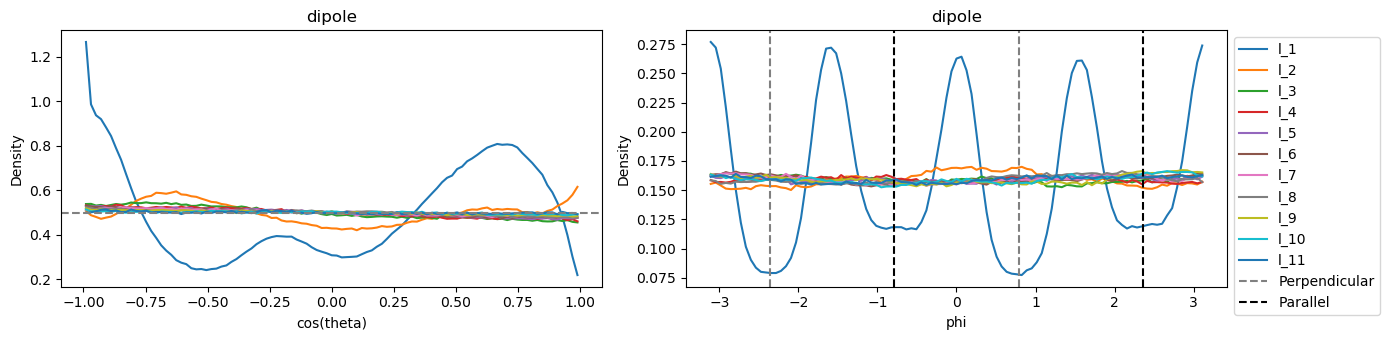

In [891]:
#print ALL histograms

hist_category='dipole'
threeshold=10
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 3.5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'
axes = axes.flatten()
# Iterate through the axes and plot on each


for ax, name_internal, x_name  in  zip(axes, name_internals+name_internals, x_labels+x_labels, ):
    for l in dict_hist[name_internal+str_hist+hist_category][1].keys():
       # print(l)
        if np.sum(dict_hist[name_internal+str_hist+hist_category][1][l])<threeshold:
            continue
        else:     
            #ACTIVATE this IF: Only for phi weighted normalization (np.sin theta )                 
            if name_internal == 'phi':
                norm_index=3
            else:
                norm_index=2
            #print(name_internal+str_hist+hist_category+region)
            ax.plot( dict_hist[name_internal+str_hist+hist_category][0] , dict_hist[name_internal+str_hist+hist_category][1][l]/(dict_hist[name_internal+str_hist+hist_category][norm_index][l])/eval('d_'+name_internal), label=l  ) 
            ax.set_title(f"{hist_category}")
            ax.set_xlabel(x_name)
            ax.set_ylabel('Density')
            
    if name_internal == 'phi':
        ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
        ax.axvline(x=-2.3562, color='grey', linestyle='--')
        ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
        ax.axvline(x=-0.7854, color='black', linestyle='--'  )    
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1)) 
    if name_internal == 'theta':
        ax.axhline(y=0.5, color='grey', linestyle='--')
        #ax.set_ylim(0.45, 0.550)    
    
# Adjust layout for better spacing
plt.tight_layout()
save_path="/data/home/salvatorer26/Desktop/group_meeting/Pres_8"
#plt.savefig(f"{save_path}/{hist_category}_large_cutoff", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

In [1]:
3.14/4 

0.785

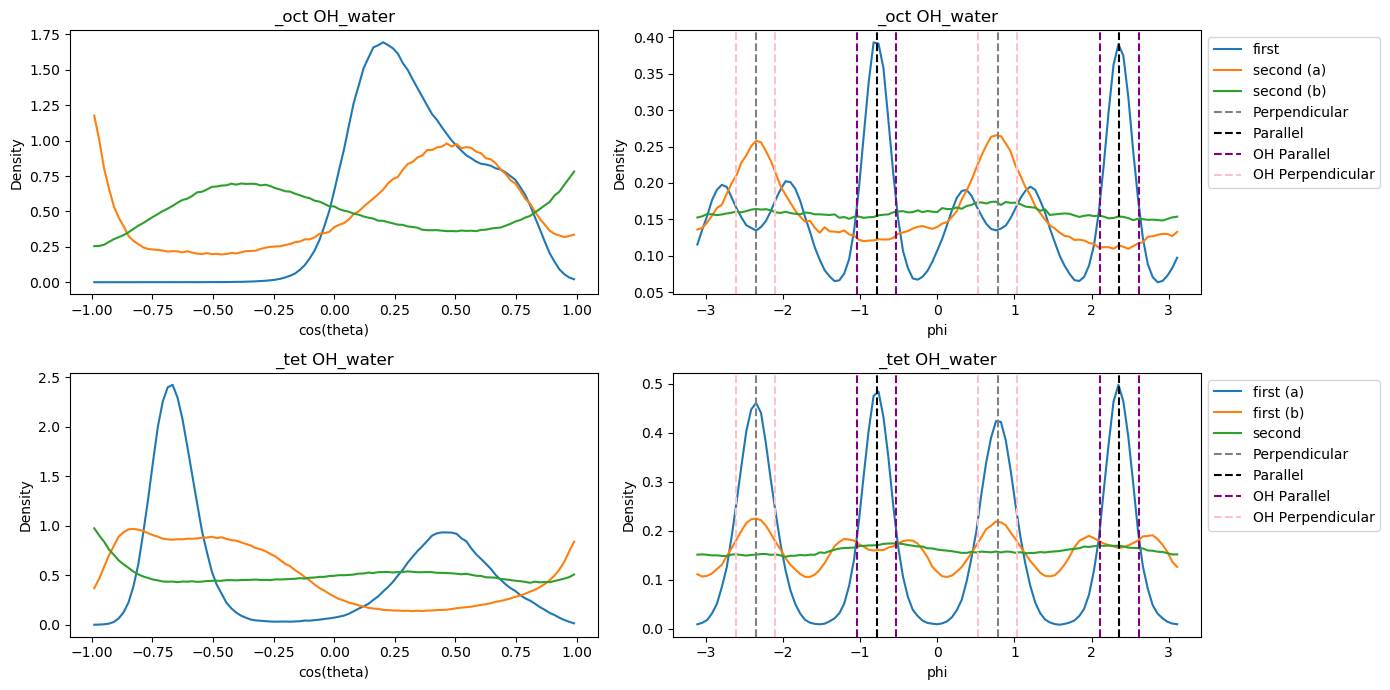

In [895]:
#OCT/TET histograms
threeshold=5000
hist_category='OH_water'
regions=['_oct', '_oct' , '_tet', '_tet']
N_break=2
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 7))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'
axes = axes.flatten()
# Iterate through the axes and plot on each

for ax, name_internal, x_name , region in  zip(axes, name_internals+name_internals, x_labels+x_labels, regions):
    lcount=0
    for l in  dict_hist[name_internal+str_hist+hist_category+region][1].keys():
        #print(l)
        if np.sum(dict_hist[name_internal+str_hist+hist_category+region][1][l])<threeshold:
            continue
        else:
            if lcount>N_break:
                break
            lcount+=1
            if name_internal=='phi':
                norm_index=3
            else:
                norm_index=2
            #print(name_internal+str_hist+hist_category+region)
            ax.plot( dict_hist[name_internal+str_hist+hist_category+region][0] , dict_hist[name_internal+str_hist+hist_category+region][1][l]/(dict_hist[name_internal+str_hist+hist_category+region][norm_index][l])/eval('d_'+name_internal), label=l  ) 
            ax.set_title(f'{region} {hist_category}')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Density')
    if name_internal == 'phi':
        ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
        ax.axvline(x=-2.3562, color='grey', linestyle='--')
        ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
        ax.axvline(x=-0.7854, color='black', linestyle='--'  ) 
           
        if hist_category == 'OH_water':
           ax.axvline(x=2.609,     color='purple', linestyle='--'  , label='OH Parallel' )  
           ax.axvline(x=2.1031,    color='purple', linestyle='--'  )
           ax.axvline(x=-1.03847,  color='purple', linestyle='--'    )
           ax.axvline(x=-0.53232,  color='purple', linestyle='--'    )

           ax.axvline(x=-2.609,     color='pink', linestyle='--', label='OH Perpendicular' )  
           ax.axvline(x=-2.1031,    color='pink', linestyle='--'    )
           ax.axvline(x=1.03847,    color='pink', linestyle='--'    )
           ax.axvline(x=0.53232,    color='pink', linestyle='--'    )
     
        if hist_category == 'dipole':
            ax.axvline(x=-3.01505,  color='pink', linestyle='--'  , label='Dipole of 1 OH Parallel' )                
            ax.axvline(x= -1.69733 ,color='pink', linestyle='--'  ) 
            ax.axvline(x= 0.1265,   color='pink', linestyle='--'  )  
            ax.axvline(x= 1.444259, color='pink', linestyle='--'  ) 

            ax.axvline(x=1.697,   color='purple', linestyle='--' ,label='Dipole of 1 OH Perpendicular' )    
            ax.axvline(x=3.01505, color='purple', linestyle='--'  )    
            ax.axvline(x=-1.4442, color='purple', linestyle='--'  )
            ax.axvline(x=-0.1265, color='purple', linestyle='--'  )
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
plt.tight_layout()


save_path="/data/home/salvatorer26/Desktop/group_meeting/Pres_8"
#plt.savefig(f"{save_path}/{hist_category}_tet_oct", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)

# Show the plots
plt.show()

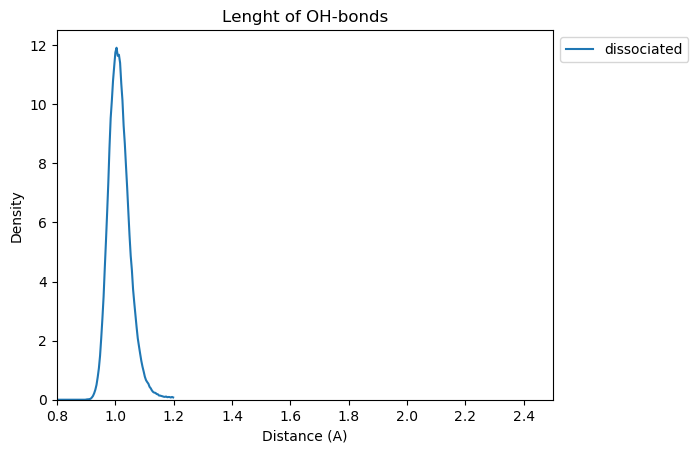

In [896]:
#dissociated bond lenght analysis

plt.plot(rho_bins_centers, dict_hist['rho_hist_OH'][1]['l_0']/d_rho/dict_hist['rho_hist_OH'][2]['l_0'], label='dissociated')
#plt.plot(rho_bins_centers, dict_hist['rho_hist_OH'][1]['l_1']/d_rho/dict_hist['rho_hist_OH'][2]['l_1'], label='OH alone')
#plt.plot(rho_bins_centers, dict_hist['rho_hist_OH_water_tet'][1]['first (a)']/d_rho/dict_hist['rho_hist_OH_water_tet'][2]['first (a)'], label='water on dissociation site')
#plt.plot(rho_bins_centers, dict_hist['rho_hist_OH_water'][1]['l_1']/d_rho/dict_hist['rho_hist_OH_water'][2]['l_1'], label='OH water first')
#plt.plot(rho_bins_centers, dict_hist['rho_hist_OH_water'][1]['l_2']/d_rho/dict_hist['rho_hist_OH_water'][2]['l_2'], label='water bulk')


#plt.axvline(x=1.0158289076851776)
               
#plt.axvline(x= 0.993875453, color='red')
#plt.axvline(x= 0.9841903, color='orange')
plt.title( "Lenght of OH-bonds")
plt.xlabel("Distance (A)")
plt.ylabel("Density")

plt.xlim(0.8,2.5)
plt.ylim(0)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))

save_path="/data/home/salvatorer26/Desktop/group_meeting/Pres_8"
#plt.savefig(f"{save_path}/bond_lenghts", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)


In [586]:
np.sum(dict_hist['rho_hist_OH'][1]['l_0'])

1454067

In [674]:
def weighted_average(values, weights):
    if len(values) != len(weights):
        raise ValueError("Length of values and weights must be the same")
    
    total_weight = sum(weights)
    weighted_sum = sum(value * weight for value, weight in zip(values, weights))
    
    return weighted_sum / total_weight

In [678]:
mean_dis=   weighted_average( rho_bins_centers,      dict_hist['rho_hist_OH'][1]['l_0'])
mean_alone=   weighted_average( rho_bins_centers,      dict_hist['rho_hist_OH'][1]['l_1'])
mean_water=   weighted_average( rho_bins_centers,      dict_hist['rho_hist_OH_water'][1]['l_2'])
print('dissociated= ', mean_dis)
print('alone= ', mean_alone)
print('water= ', mean_water)

dissociated=  1.0158289076851776
alone=  0.984190382941703
water=  0.9938754536045837


In [669]:
#2D ANGULAR HISTOGRAMS


path_of_runs='/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/'
run_folder='full_coverage_big/run_2/'

folder_hist_ang=path_of_runs+run_folder+"histogram_angular_combo/"

combo_dict_hist_u={}
combo_dict_hist_d={}
surface_selection_u='_u'
surface_selection_d='_d'

hist_str='_hist_'
category=['dipole', 'OH_water', 'OH' ]
regions=['','_oct', '_tet' ]
py_extension='.npy'

for cat in category:
    for reg in regions:
        file='combo'+hist_str+cat+reg
        combo_dict_hist_u[file+surface_selection_u] =   np.load(folder_hist_ang+file+surface_selection_u+py_extension, allow_pickle=True)
        combo_dict_hist_d[file+surface_selection_d] =   np.load(folder_hist_ang+file+surface_selection_d+py_extension, allow_pickle=True)
     

In [670]:
print(combo_dict_hist_d['combo_hist_dipole_d'][0]['l_1'])



[[174. 192. 171. ... 224. 202. 181.]
 [150. 166. 161. ... 169. 170. 145.]
 [146. 156. 149. ... 162. 127. 179.]
 ...
 [ 54.  63.  68. ...  77.  53.  71.]
 [ 41.  35.  51. ...  54.  58.  46.]
 [ 31.  48.  28. ...  32.  39.  42.]]


In [671]:
#unify up and down

combo_dict_hist={}
for i, dict_tot in combo_dict_hist_u.items():
    print(i[:-2]) #remove '_u'
    combo_dict_hist[i[:-2]]=[{}, {} ]
    for l in dict_tot[1].keys():
        combo_dict_hist[i[:-2]][0][l]=    combo_dict_hist_u[i][0][l]+combo_dict_hist_d[i[:-2]+'_d'][0][l]
        combo_dict_hist[i[:-2]][1][l]=    combo_dict_hist_u[i][1][l]+combo_dict_hist_d[i[:-2]+'_d'][1][l]
      

combo_hist_dipole
combo_hist_dipole_oct
combo_hist_dipole_tet
combo_hist_OH_water
combo_hist_OH_water_oct
combo_hist_OH_water_tet
combo_hist_OH
combo_hist_OH_oct
combo_hist_OH_tet


In [757]:
phi_bins=np.load(folder_hist_ang+'phi_bins.npy')
theta_bins=np.load(folder_hist_ang+'theta_bins.npy')


n_bins=len(theta_bins)
phi_bin_centers=(phi_bins[1:]+phi_bins[:-1])/2 
theta_bin_centers=(theta_bins[1:]+theta_bins[:-1])/2 

d_theta=(theta_bins[-1]-theta_bins[0])/(n_bins-2)
d_phi=(phi_bins[-1]-phi_bins[0])/(n_bins-2)


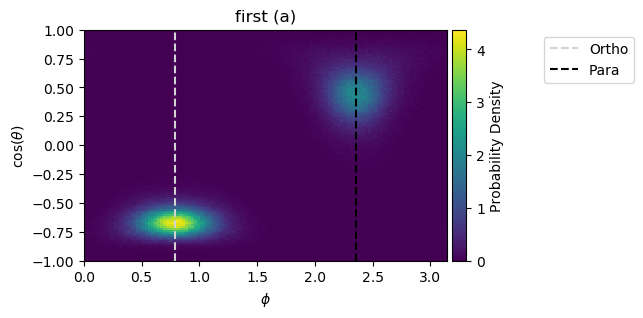

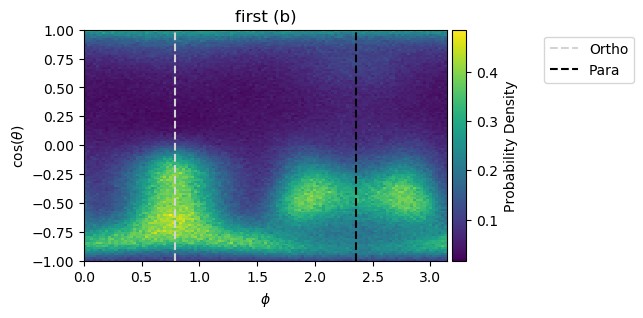

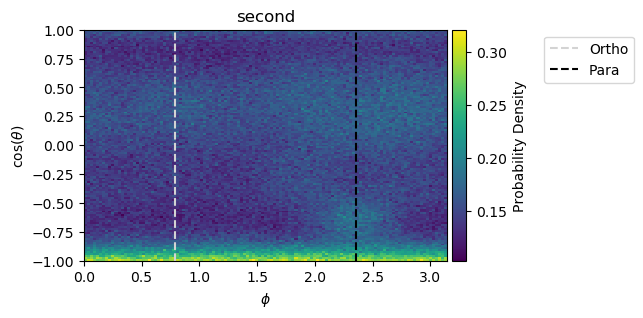

In [858]:

from mpl_toolkits.axes_grid1 import make_axes_locatable

c = 'combo_hist_'
hist_category = 'OH_water'
reg = '_tet'
regions = range(len(combo_dict_hist[c + hist_category + reg][0]))

threshold = 1000

for i, key in enumerate(combo_dict_hist[c + hist_category + reg][0].keys()):
    if combo_dict_hist[c + hist_category + reg][1][key] > threshold:
        #plt.figure()
        plt.figure(figsize=(10, 3))
        ax = plt.gca()
         
        im = plt.imshow(combo_dict_hist[c + hist_category + reg][0][key] / combo_dict_hist[c + hist_category + reg][1][key]   /(d_theta*d_phi) ,
                            interpolation='nearest', origin='lower', extent=(0, np.pi, -1, 1))
        plt.axvline(x=0.7854, color='lightgrey', linestyle='--', label='Ortho')
        plt.axvline(x=2.356, color='black', linestyle='--', label='Para')
        
        #if hist_category == 'OH_water':
        #   ax.axvline(x=2.609,     color='purple', linestyle='--'  , label='OH Parallel' )  
        #   ax.axvline(x=2.1031,    color='purple', linestyle='--'  )
        #   ax.axvline(x=1.03847,     color='pink', linestyle='--', label='OH Perpendicular' )  
        #   ax.axvline(x=0.53232,    color='pink', linestyle='--'    )
        #if hist_category == 'dipole':
        #    ax.axvline(x=0.1265,  color='pink', linestyle='--'  , label='Dipole of 1 OH Parallel' )         
        #    ax.axvline(x= 1.444259 ,color='pink', linestyle='--'  ) 
        #    ax.axvline(x=1.697,   color='purple', linestyle='--' ,label='Dipole of 1 OH Perpendicular' )    
        #    ax.axvline(x=3.01505, color='purple', linestyle='--'  )    
     
        plt.xlabel(r'$\phi$')
        plt.ylabel(r'cos($\theta$)')
        #plt.legend()
        plt.legend(loc='upper left', bbox_to_anchor=(1.25, 1))
        plt.title(f'{key}')
       
        #create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be fixed at 0.05 inch.
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="4%", pad=0.05)
   
        plt.colorbar(im, cax=cax, label ='Probability Density')
         #plt.colorbar(orientation='vertical', label ='Frequency')
        #plt.tight_layout()
        save_path="/data/home/salvatorer26/Desktop/group_meeting/angular_combo"
        #plt.savefig(f"{save_path}/{c}{hist_category}_{key}{reg}", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
        plt.show()
        
        

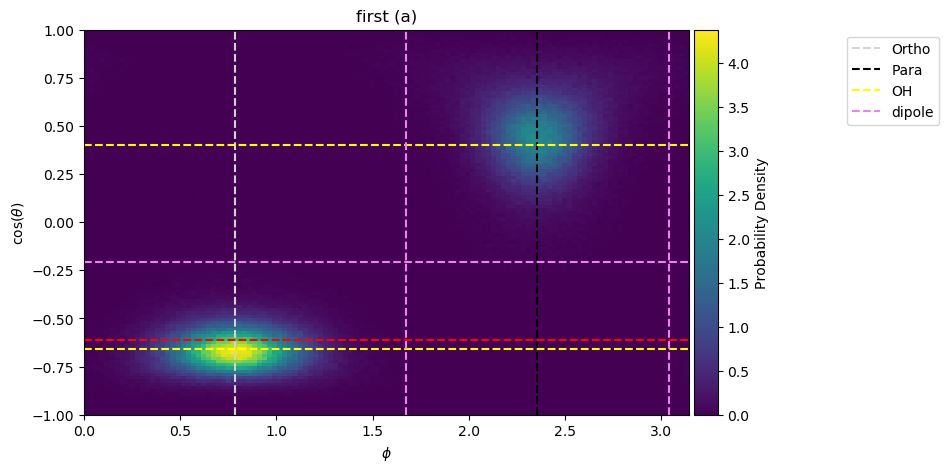

In [860]:

from mpl_toolkits.axes_grid1 import make_axes_locatable

c = 'combo_hist_'
hist_category = 'OH_water'
reg = '_tet'
regions = range(len(combo_dict_hist[c + hist_category + reg][0]))

threshold = 1000

count=0
for i, key in enumerate(combo_dict_hist[c + hist_category + reg][0].keys()):
    if combo_dict_hist[c + hist_category + reg][1][key] > threshold:
        #plt.figure()
        plt.figure(figsize=(25, 5))
        ax = plt.gca()
         
        im = plt.imshow(combo_dict_hist[c + hist_category + reg][0][key] / combo_dict_hist[c + hist_category + reg][1][key]/ (d_phi*d_theta),
                            interpolation='nearest', origin='lower', extent=(0, np.pi, -1, 1))
        plt.axvline(x=0.7854, color='lightgrey', linestyle='--', label='Ortho')
        plt.axvline(x=2.356, color='black', linestyle='--', label='Para')
        #OHs
        plt.axhline(y=-0.66  ,  color='yellow', linestyle='--', label='OH' )
        plt.axhline(y=0.4  ,  color='yellow', linestyle='--' )
        #dipoles
        plt.axvline(x=1.67539631, color='violet', linestyle='--', label='dipole')
        plt.axvline(x=3.036992, color='violet', linestyle='--')
        plt.axhline(y=-0.205 ,  color='violet', linestyle='--' )
        plt.axhline(y=-0.61, color='red', linestyle='--')
        
        plt.xlabel(r'$\phi$')
        plt.ylabel(r'cos($\theta$)')
        #plt.legend()
        plt.legend(loc='upper left', bbox_to_anchor=(1.25, 1))
        plt.title(f'{key}')
       
        #create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be fixed at 0.05 inch.
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="4%", pad=0.05)
   
        plt.colorbar(im, cax=cax, label ='Probability Density')
         #plt.colorbar(orientation='vertical', label ='Frequency')
        #plt.tight_layout()
        save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
        #plt.savefig(f"{save_path}/{c}{hist_category}_{key}{reg}_plus", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
        
      
        plt.show()
        
        count+=1
        if count >=1:
            break
        
        
        
        

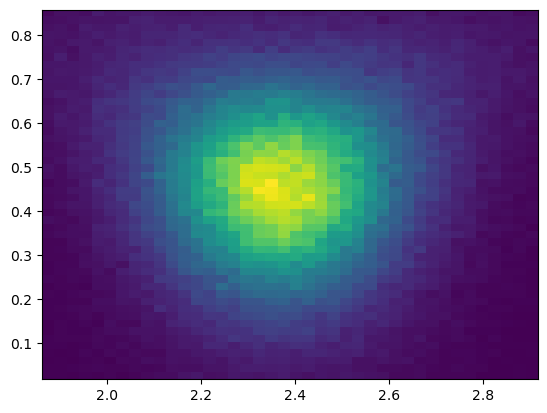

In [829]:
OH_theta_start=60
OH_theta_end=110

OH_phi_start=70
OH_phi_end=110
plt.imshow( np.array(norm_OH_water_tet_a[OH_theta_start:OH_theta_end, OH_phi_start:OH_phi_end]) , 
           interpolation='nearest', origin='lower',extent= ( phi_bin_centers[OH_phi_start] ,phi_bin_centers[OH_phi_end], theta_bin_centers[OH_theta_start] ,theta_bin_centers[OH_theta_end] ), aspect='auto' )




In [831]:
norm_OH_water_tet_a=combo_dict_hist["combo_hist_OH_water_tet"][0]['first (a)'] / np.sum(combo_dict_hist["combo_hist_OH_water_tet"][0]['first (a)'])
norm_dipole_tet_a=combo_dict_hist["combo_hist_dipole_tet"][0]['first (a)'] / np.sum(combo_dict_hist["combo_hist_dipole_tet"][0]['first (a)'])

up_contribution=np.sum(norm_OH_water_tet_a  [60:110,70:110]  )
down_contribution=np.sum(norm_OH_water_tet_a  [8:45, 0:60]  )
dipole_down=np.sum(norm_dipole_tet_a  [:4,: ]  )
print('OH_up fraction =', up_contribution)
print('OH_down fraction=', down_contribution)
print('OH difference= ', down_contribution-  up_contribution  )
print('OH sum= ', down_contribution+  up_contribution  )
print('dipole_down fraction=', dipole_down)


OH_up fraction = 0.4108095923679886
OH_down fraction= 0.5406672192894435
OH difference=  0.12985762692145492
OH sum=  0.9514768116574321
dipole_down fraction= 0.12610251616829585


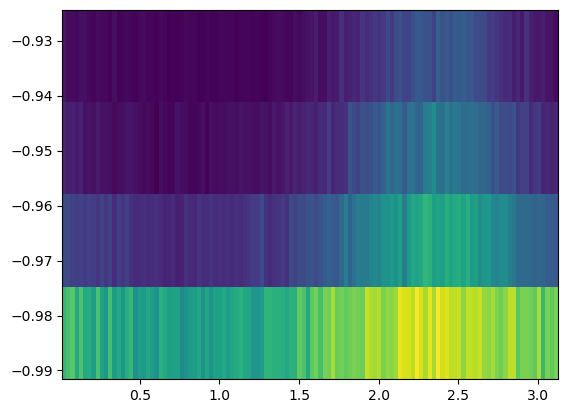

In [819]:
dipole_theta_start=0
dipole_theta_end=4

dipole_phi_start=0
dipole_phi_end=118
plt.imshow( np.array(norm_dipole_tet_a[dipole_theta_start:dipole_theta_end, dipole_phi_start:dipole_phi_end]) , 
           interpolation='nearest', origin='lower',extent= ( phi_bin_centers[dipole_phi_start] ,phi_bin_centers[dipole_phi_end], theta_bin_centers[dipole_theta_start] ,theta_bin_centers[dipole_theta_end] ), aspect='auto' )




In [766]:
from scipy import integrate


def integrate_2d_array(arr, x, y):
    # Integrate along the x-axis
    integrated_x = np.trapz(arr, x, axis=1)
    
    # Integrate along the y-axis
    integrated_2d = np.trapz(integrated_x, y)
    
    return integrated_2d


integral=integrate_2d_array(norm_OH_water_tet_a, theta_bin_centers, phi_bin_centers)

print(integral)

0.9826300765932654


In [710]:
print(np.sum(combo_dict_hist["combo_hist_OH_water_tet"][0]['first (a)']))
combo_dict_hist["combo_hist_OH_water_tet"][1]['first (a)']

687630.0


687630

In [433]:
from scipy.spatial.transform import Rotation

import math

def spherical_to_cartesian(radius, theta, phi):
    x = radius * np.sin(theta) * np.cos(phi)
    y = radius * np.sin(theta) * np.sin(phi)
    z = radius * np.cos(theta)
    return x, y, z


def rotation(point, angle, axis):
    axis=axis/np.linalg.norm(axis) #if is not normalized should be
    r = Rotation.from_rotvec(angle * axis)
    rotated_point = r.apply(point)
    return rotated_point

phi_pi_periodicity=True
def cartesian_internal(u, phi_pi_periodicity ):  
    x=u[0]
    y=u[1]
    z=u[2]
    # Calculate radial distance
    r = math.sqrt(x**2 + y**2 + z**2)

    # Calculate polar angle (theta)
    theta = math.acos(z / r) if r != 0 else 0

    # Calculate azimuthal angle (phi)
    phi = math.atan2(y, x)
    if phi_pi_periodicity:
        if phi<0:
            phi = phi+np.pi

    return np.array([r, theta, phi])  



In [856]:

#tetrahedral first (a)
#2 clouds identical pointing in the given direciton are in agreement with a water molecule 
OH_theta_1=np.arccos(-0.66) 

OH_phi_1=np.pi/4
OH_theta_2=np.arccos(0.4 ) 
OH_phi_2=np.pi/4+np.pi/2


OH_1= spherical_to_cartesian(1, OH_theta_1, OH_phi_1)
OH_2= spherical_to_cartesian(1, OH_theta_2, OH_phi_2)
#print(OH_1, OH_2)

angle_between=np.arccos(np.dot(OH_1, OH_2))*180/np.pi
print('angle between  = ', angle_between)


dipole_1=np.array(OH_1)+np.array(OH_2)
dipole_2=-np.array(OH_1)+np.array(OH_2)

dipole_int_1=cartesian_internal(dipole_1, phi_pi_periodicity)
dipole_int_2=cartesian_internal(dipole_2, phi_pi_periodicity)
print("cos(theta_dipole)= " , np.cos(dipole_int_1[1]))
print("phi_dipole_1= " , dipole_int_1[2])
print("phi_dipole_2="   , dipole_int_2[2])

### the Bottom cloud is made of another elongated contribution coming from a molecule pointing down: dipole is okay 

angle_theta_down=(180-80.5)/2

print('angle theta_down = ', -np.cos(angle_theta_down*np.pi/180))




angle between  =  105.30754110852001
cos(theta_dipole)=  -0.2142986538536307
phi_dipole_1=  1.6695574639701554
phi_dipole_2= 3.0428315164145343
angle theta_down =  -98


In [857]:
#water should be like -0.61!
180-   (np.arccos(-0.61)*180/np.pi-90)*2



#np.pi-np.arccos(-0.67)

104.82099407028628

In [893]:
gamma=104.5/180*np.pi
c_gamma=np.cos(gamma)
#OH_1 is the  OH of water which is pointing in the peaked direction of the plot.
binning=80
theta_OH_1=np.arccos(0.14)  #got from the plot
phi_OH_1=np.pi/2+np.pi/4      #Parallel


#tranfrom in cartesian
OH_1= spherical_to_cartesian(1, theta_OH_1 , phi_OH_1)   #
OH_1_opposite=[-OH_1[0],  -OH_1 [1], OH_1[2]    ]


#OH_2 is the second OH vector of water, defined such that: in the xy plane (z=0), at 104.5 ddegree from OH_1, normlized
#solving the equations:

OH_2y=(c_gamma*OH_1[1] + np.sqrt((c_gamma*OH_1[1])**2  -  (OH_1[0]**2+ OH_1[1]**2 )*( c_gamma**2 - OH_1[0]**2  )      )) / (OH_1[0]**2+OH_1[1]**2) 
OH_2x=np.sqrt(1-OH_2y**2 )
OH_2=[OH_2x,   OH_2y, 0  ]
print("OH_2 chosen is =",  OH_2)



#rotating OH_2 around OH_1 with angles form 0 to pi


rotated_OH=[]
cart_rotated_OH=[]
rotated_OH_opposite=[]
for angle in np.linspace(- np.pi,np.pi,binning):
    rotated_OH.append( cartesian_internal(rotation(OH_2, angle, OH_1) , phi_pi_periodicity ) )
    cart_rotated_OH.append(rotation(OH_2, angle, OH_1))

rotated_OH=np.array(rotated_OH)
rotated_OH_opposite=np.array(rotated_OH_opposite)
cart_rotated_OH=np.array(cart_rotated_OH)


dipole=[]

for OH_rot in cart_rotated_OH:
    dipole.append( cartesian_internal( OH_1+  OH_rot, phi_pi_periodicity))
dipole=np.array(dipole)

OH_2 chosen is = [0.8629322975462559, 0.5053195522157637, 0]


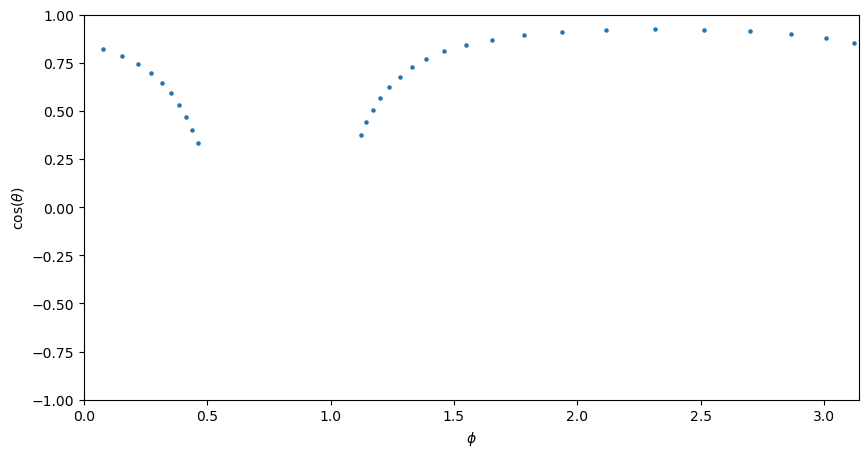

In [926]:
start_ind=6
end_ind=int((len(rotated_OH) -start_ind)   /2)-1
#end_ind=len(rotated_OH)
plt.figure(figsize=(10, 5))
plt.scatter(rotated_OH[start_ind:end_ind,2],  np.cos(rotated_OH[start_ind:end_ind,1]), s=5)
#plt.scatter(rotated_OH_opposite[:,2],  np.cos(rotated_OH_opposite[:,1]))
plt.xlabel(r'$\phi$')
plt.ylabel(r'cos($\theta$)')
plt.ylim(-1,1)
plt.xlim(0,np.pi)

save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/simulation_OH", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)

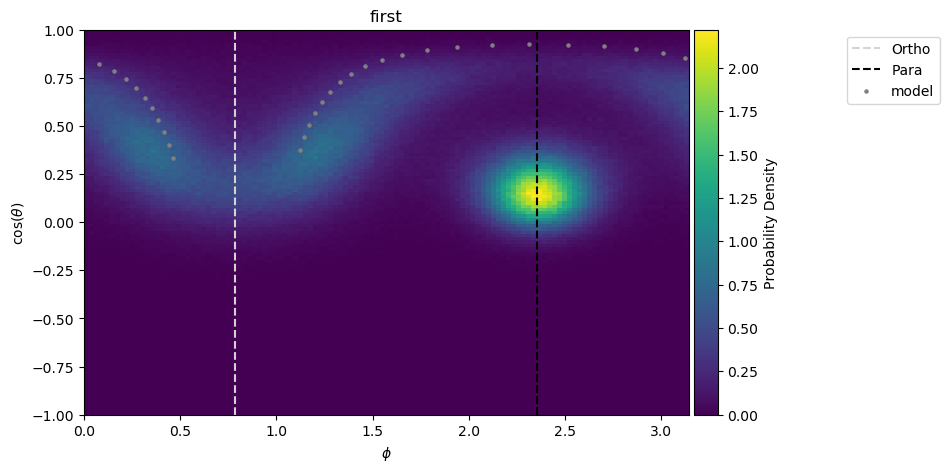

In [927]:

from mpl_toolkits.axes_grid1 import make_axes_locatable

c = 'combo_hist_'
hist_category = 'OH_water'
reg = '_oct'
regions = range(len(combo_dict_hist[c + hist_category + reg][0]))

threshold = 1000

count=0
for i, key in enumerate(combo_dict_hist[c + hist_category + reg][0].keys()):
    if combo_dict_hist[c + hist_category + reg][1][key] > threshold:
        #plt.figure()
        plt.figure(figsize=(25, 5))
        ax = plt.gca()
         
        im = plt.imshow(combo_dict_hist[c + hist_category + reg][0][key] / combo_dict_hist[c + hist_category + reg][1][key]/ (d_phi*d_theta),
                            interpolation='nearest', origin='lower', extent=(0, np.pi, -1, 1))
        plt.axvline(x=0.7854, color='lightgrey', linestyle='--', label='Ortho')
        
        plt.scatter(rotated_OH[start_ind:end_ind,2],  np.cos(rotated_OH[start_ind:end_ind,1]), color='gray', s=5, label='model')
        
        plt.axvline(x=2.356, color='black', linestyle='--', label='Para')
        #OHs
        #plt.axhline(y=-0.66  ,  color='yellow', linestyle='--', label='OH' )
        #plt.axhline(y=0.4  ,  color='yellow', linestyle='--' )
        ##dipoles
        #plt.axvline(x=1.67539631, color='violet', linestyle='--', label='dipole')
        #plt.axvline(x=3.036992, color='violet', linestyle='--')
        #plt.axhline(y=-0.205 ,  color='violet', linestyle='--' )
        #plt.axhline(y=-0.61, color='red', linestyle='--')
        
        plt.xlabel(r'$\phi$')
        plt.ylabel(r'cos($\theta$)')
        #plt.legend()
        plt.legend(loc='upper left', bbox_to_anchor=(1.25, 1))
        plt.title(f'{key}')
       
        #create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be fixed at 0.05 inch.
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="4%", pad=0.05)
   
        plt.colorbar(im, cax=cax, label ='Probability Density')
         #plt.colorbar(orientation='vertical', label ='Frequency')
        #plt.tight_layout()
        save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
        #plt.savefig(f"{save_path}/{c}{hist_category}_{key}{reg}_plus", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
        
        plt.show()
        
        count+=1
        if count >=1:
            break
        
        
        
        

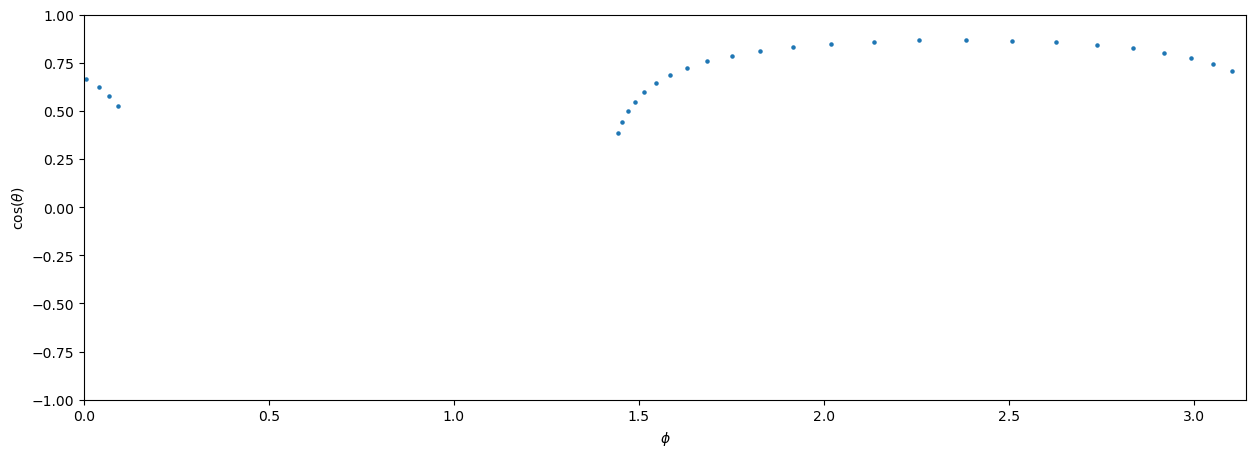

In [917]:

start_ind=8
end_ind=int((len(dipole)-start_ind)/2)
plt.figure(figsize=(15, 5))
plt.ylim(-1,1)
plt.xlim(0,np.pi)
plt.scatter(dipole[start_ind:end_ind,2],  np.cos(dipole[start_ind:end_ind,1]),s=5)
plt.xlabel(r'$\phi$')
plt.ylabel(r'cos($\theta$)')

save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/simulation_dipole", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
plt.show()



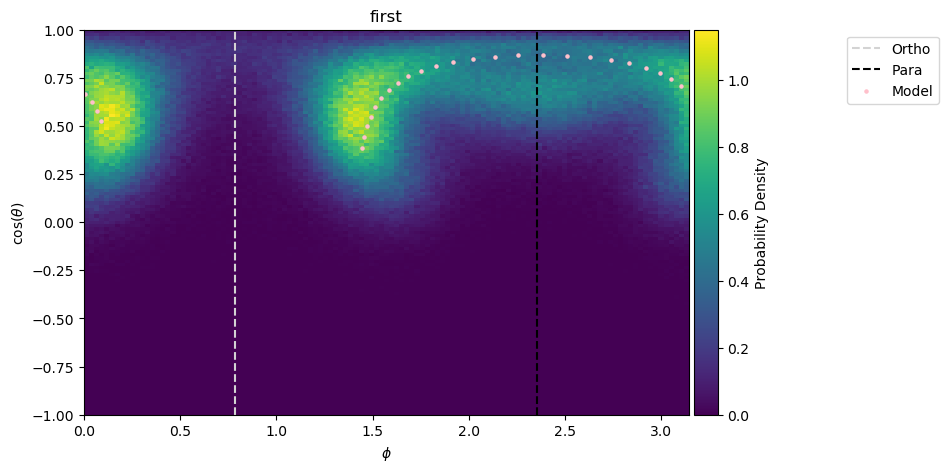

In [918]:

from mpl_toolkits.axes_grid1 import make_axes_locatable

c = 'combo_hist_'
hist_category = 'dipole'
reg = '_oct'
regions = range(len(combo_dict_hist[c + hist_category + reg][0]))

threshold = 1000

count=0
for i, key in enumerate(combo_dict_hist[c + hist_category + reg][0].keys()):
    if combo_dict_hist[c + hist_category + reg][1][key] > threshold:
        #plt.figure()
        plt.figure(figsize=(25, 5))
        ax = plt.gca()
        
        im = plt.imshow(combo_dict_hist[c + hist_category + reg][0][key] / combo_dict_hist[c + hist_category + reg][1][key]/ (d_phi*d_theta),
                            interpolation='nearest', origin='lower', extent=(0, np.pi, -1, 1))
        
        plt.scatter(dipole[start_ind:end_ind,2],  np.cos(dipole[start_ind:end_ind,1]), color='pink', label='Model' , s=5)
        plt.axvline(x=0.7854, color='lightgrey', linestyle='--', label='Ortho')
    
        plt.axvline(x=2.356, color='black', linestyle='--', label='Para')

        plt.xlabel(r'$\phi$')
        plt.ylabel(r'cos($\theta$)')
        #plt.legend()
        plt.legend(loc='upper left', bbox_to_anchor=(1.25, 1))
        plt.title(f'{key}')
       
        #create an axes on the right side of ax. The width of cax will be 5% of ax and the padding between cax and ax will be fixed at 0.05 inch.
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="4%", pad=0.05)
   
        plt.colorbar(im, cax=cax, label ='Probability Density')
         #plt.colorbar(orientation='vertical', label ='Frequency')
        #plt.tight_layout()
        save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
        #plt.savefig(f"{save_path}/{c}{hist_category}_{key}{reg}_plus", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
        
        plt.show()
        
        count+=1
        if count >=1:
            break
        
        
        
        

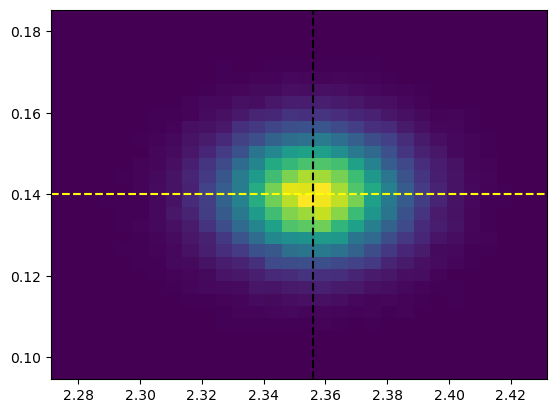

In [420]:
#2D distribution

# gamma=104.5/180*np.pi
c_gamma=np.cos(gamma)
#OH_1 is the  OH of water which is pointing in the peaked direction of the plot.


num_samples = 100000

mu_theta=0.14
sigma_theta=0.0001


mu_phi=np.pi/2+np.pi/4      #Parallel
sigma_phi=0.00035


mean = [ mu_phi, mu_theta]
cov = [ [ sigma_phi,0], [0, sigma_theta]]


samples = np.random.multivariate_normal(mean, cov, num_samples)
plt.hist2d(samples[:, 0], samples[:, 1], bins=30, cmap='viridis')
plt.axhline(y=0.44  ,  color='yellow', linestyle='--' )
plt.axhline(y=0.14  ,  color='yellow', linestyle='--' )
plt.axvline(x=2.75, color='black', linestyle='--', label='Para')
plt.axvline(x=2.356, color='black', linestyle='--', label='Para')
plt.show()



In [422]:
sample_rotated_OH=[]
sample_dipole=[]
for phi_OH_1,  theta_OH_1  in samples:
 
    #tranfrom in cartesian
    OH_1= spherical_to_cartesian(1, theta_OH_1 , phi_OH_1)   #
    #OH_2 is the second OH vector of water, defined such that: in the xy plane (z=0), at 104.5 ddegree from OH_1, normlized
    #solving the equations:
    
    OH_2y=(c_gamma*OH_1[1] + np.sqrt((c_gamma*OH_1[1])**2  -  (OH_1[2]**2+ OH_1[1]**2 )*( c_gamma**2 - OH_1[2]**2  )      )) / (OH_1[2]**2+OH_1[1]**2) 
    OH_2x=np.sqrt(1-OH_2y**2 )
    OH_2=[0 ,   OH_2y, OH_2x ]
    print("OH_2 chosen is =",  OH_2)
    
    
    #rotating OH_2 around OH_1 with angles form 0 to pi
    
    
    rotated_OH=[]
    cart_rotated_OH=[]
   
    for angle in np.random.uniform(- np.pi,np.pi,10):
        rotated_OH.append( cartesian_internal(rotation(OH_2, angle, OH_1) , phi_pi_periodicity ) )
        cart_rotated_OH.append(rotation(OH_2, angle, OH_1))
    
    
    rotated_OH=np.array(rotated_OH)
    cart_rotated_OH=np.array(cart_rotated_OH)
    
    
    dipole=[]
    
    for OH_rot in cart_rotated_OH:
        dipole.append( cartesian_internal( OH_1+  OH_rot, phi_pi_periodicity))
    dipole=np.array(dipole)
    
    sample_rotated_OH.append(rotated_OH)
    sample_dipole.append(dipole)

OH_2 chosen is = [0, 0.9374956993144563, 0.34799685884630993]
OH_2 chosen is = [0, 0.9405922537214908, 0.33953823383991194]
OH_2 chosen is = [0, 0.9384828077459986, 0.34532596132521964]
OH_2 chosen is = [0, 0.9374940915489013, 0.34800119009983327]
OH_2 chosen is = [0, 0.9372379977452349, 0.34869031472425954]
OH_2 chosen is = [0, 0.9379740396776259, 0.34670549590514926]
OH_2 chosen is = [0, 0.9405785998655536, 0.3395760555088578]
OH_2 chosen is = [0, 0.9364974839821277, 0.3506742968840807]
OH_2 chosen is = [0, 0.9382535607739597, 0.34594834252383044]
OH_2 chosen is = [0, 0.9405684214176062, 0.3396042470759049]
OH_2 chosen is = [0, 0.9396487977985045, 0.34214052200203526]
OH_2 chosen is = [0, 0.9401332939407816, 0.34080696827391305]
OH_2 chosen is = [0, 0.9405780526179388, 0.3395775713050642]
OH_2 chosen is = [0, 0.9384547551404046, 0.34540218956220203]
OH_2 chosen is = [0, 0.9358351945321453, 0.35243792173229854]
OH_2 chosen is = [0, 0.9374389217672671, 0.3481497780493673]
OH_2 chosen i

In [423]:
all_sample_dipole=np.array(sample_dipole).reshape(-1, array_3d.shape[-1])[:,1:]

all_sample_rotated_OH=np.array(sample_rotated_OH).reshape(-1, array_3d.shape[-1])[:,1:]

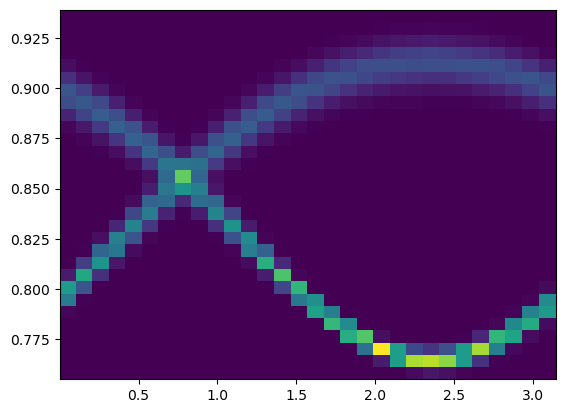

In [431]:
plt.hist2d(all_sample_dipole[:, 1], np.cos(all_sample_dipole[:, 0]), bins=30, cmap='viridis')
plt.show()